In [10]:
import json
import heapq
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

torch.manual_seed(0)
rng = np.random.default_rng(0)

# same data and split as every other notebook
images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())
image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)

run_dir = Path("src/rover-2/01-basic-mlp")
run_dir.mkdir(parents=True, exist_ok=True)

cuda


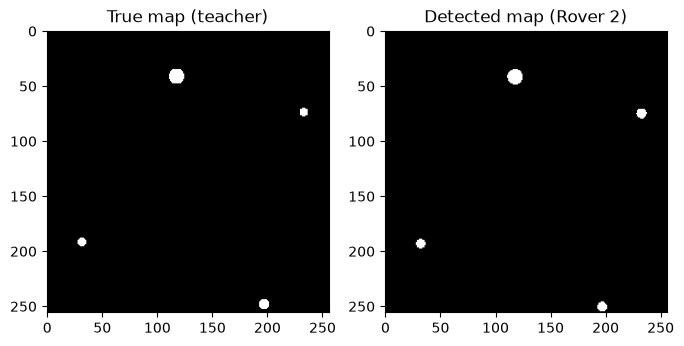

In [11]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# load the trained Faster R-CNN
detector = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=256)
in_features = detector.roi_heads.box_predictor.cls_score.in_features
detector.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=2)
detector.load_state_dict(torch.load("src/faster-rcnn/01-baseline/model.pt", map_location=device))
detector.to(device)
detector.eval()


def make_mask(boxes):
    mask = np.zeros((256, 256), dtype=np.uint8)
    yy, xx = np.mgrid[0:256, 0:256]
    for x, y, w, h in boxes:
        cx, cy, r = x + w / 2, y + h / 2, max(w, h) / 2
        mask[(xx + 0.5 - cx) ** 2 + (yy + 0.5 - cy) ** 2 <= r ** 2] = 1
    return mask


def detect_boxes(image_id):
    image = Image.open(images_path / f"{image_id}.png").convert("RGB")
    image = torch.tensor(np.array(image), dtype=torch.float32).permute(2, 0, 1) / 255.0
    with torch.no_grad():
        out = detector([image.to(device)])[0]
    keep = out["scores"] > 0.8   # best cutoff on validation
    return [[x1, y1, x2 - x1, y2 - y1] for x1, y1, x2, y2 in out["boxes"][keep].cpu().tolist()]


def get_maps(image_id):
    true_boxes = [b for b in data[image_id] if b[2] > 0 and b[3] > 0]
    return make_mask(true_boxes), make_mask(detect_boxes(image_id))


# quick check
true_map, detected_map = get_maps(train_ids[0])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(true_map, cmap="gray")
axes[0].set_title("True map (teacher)")
axes[1].imshow(detected_map, cmap="gray")
axes[1].set_title("Detected map (Rover 2)")
plt.show()

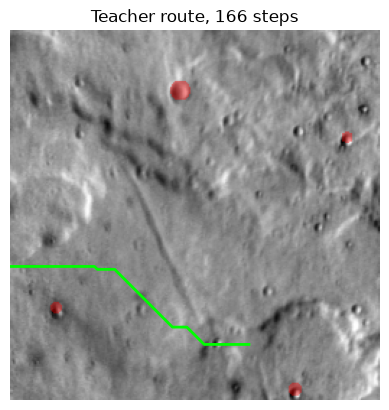

In [12]:
moves = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]


def heuristic(a, b):
    dy, dx = abs(a[0] - b[0]), abs(a[1] - b[1])
    return max(dy, dx) + (2 ** 0.5 - 1) * min(dy, dx)


def astar(blocked, start, goal):
    open_list = [(heuristic(start, goal), 0.0, start)]
    came_from = {start: None}
    cost_so_far = {start: 0.0}

    while open_list:
        _, cost, cell = heapq.heappop(open_list)
        if cell == goal:
            path = []
            while cell is not None:
                path.append(cell)
                cell = came_from[cell]
            return path[::-1]
        if cost > cost_so_far[cell]:
            continue

        for dy, dx in moves:
            ny, nx = cell[0] + dy, cell[1] + dx
            if not (0 <= ny < 256 and 0 <= nx < 256) or blocked[ny, nx]:
                continue
            new_cost = cost + (2 ** 0.5 if dy and dx else 1.0)
            if new_cost < cost_so_far.get((ny, nx), float("inf")):
                cost_so_far[(ny, nx)] = new_cost
                came_from[(ny, nx)] = cell
                heapq.heappush(open_list, (new_cost + heuristic((ny, nx), goal), new_cost, (ny, nx)))
    return None


def pick_start_goal(free, rng, min_distance=150):
    cells = np.argwhere(free)
    for _ in range(200):
        a, b = cells[rng.integers(len(cells))], cells[rng.integers(len(cells))]
        if np.hypot(*(a - b)) >= min_distance:
            return tuple(int(v) for v in a), tuple(int(v) for v in b)
    return None


# check: the teacher drives one train route on the true map
image_id = train_ids[0]
true_map, detected_map = get_maps(image_id)
start, goal = pick_start_goal((true_map == 0) & (detected_map == 0), rng)
path = astar(true_map, start, goal)

ys, xs = zip(*path)
plt.imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
plt.imshow(np.ma.masked_where(true_map == 0, true_map), cmap="autumn", alpha=0.4)
plt.plot(xs, ys, color="lime", linewidth=2)
plt.title(f"Teacher route, {len(path)} steps")
plt.axis("off")
plt.show()

(227,)
[-0.31103906 -0.95039713]


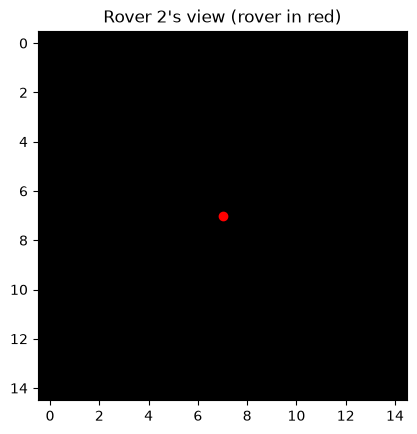

In [13]:
window = 15
half = window // 2   # 7 cells on each side of the rover


def observe(detected_map, cell, goal):
    # pad the map with 1s (crater) so the window never goes outside
    padded = np.pad(detected_map, half, constant_values=1)
    y, x = cell
    view = padded[y:y + window, x:x + window]   # centered on the rover

    dy, dx = goal[0] - y, goal[1] - x
    length = max((dy ** 2 + dx ** 2) ** 0.5, 1e-6)
    direction = [dy / length, dx / length]

    return np.concatenate([view.flatten(), direction]).astype(np.float32)


# check at the start of the route above
x = observe(detected_map, start, goal)
print(x.shape)          # (227,)
print(x[-2:])           # the direction to the goal
plt.imshow(x[:225].reshape(window, window), cmap="gray")
plt.scatter(half, half, color="red")
plt.title("Rover 2's view (rover in red)")
plt.show()

In [14]:
def make_data(ids, n_routes):
    X, Y = [], []
    for image_id in tqdm(ids[:n_routes], mininterval=1.0):
        true_map, detected_map = get_maps(image_id)
        pair = pick_start_goal((true_map == 0) & (detected_map == 0), rng)
        if pair is None:
            continue
        start, goal = pair
        path = astar(true_map, start, goal)   # the teacher knows every crater
        if path is None:
            continue

        for cell, next_cell in zip(path, path[1:]):
            move = (next_cell[0] - cell[0], next_cell[1] - cell[1])
            X.append(observe(detected_map, cell, goal))
            Y.append(moves.index(move))   # label: 0 to 7

    return torch.tensor(np.array(X)), torch.tensor(Y)


X_train, Y_train = make_data(train_ids, 500)
X_val, Y_val = make_data(val_ids, 100)

print(X_train.shape, Y_train.shape)
print(X_val.shape, Y_val.shape)
print("moves used by the teacher:", torch.bincount(Y_train, minlength=8).tolist())

100%|██████████| 100/100 [00:04<00:00, 22.64it/s]

torch.Size([87721, 227]) torch.Size([87721])
torch.Size([17561, 227]) torch.Size([17561])
moves used by the teacher: [14238, 11859, 10056, 11944, 9351, 9884, 9562, 10827]


In [15]:
from torch.utils.data import TensorDataset, DataLoader

model = nn.Sequential(
    nn.Linear(227, 128),
    nn.ReLU(),
    nn.Linear(128, 8),
).to(device)
print(sum(p.numel() for p in model.parameters()), "parameters")

train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=256, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, Y_val), batch_size=256)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 10

history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_acc = 0

for epoch in range(epochs):
    # train
    model.train()
    total_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    train_loss = total_loss / len(train_loader)

    # validate
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += loss_fn(out, y).item()
            correct += (out.argmax(dim=1) == y).sum().item()
    val_loss = total_loss / len(val_loader)
    val_acc = correct / len(Y_val)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), run_dir / "model.pt")

    print(f"epoch {epoch + 1}: train loss {train_loss:.4f}, val loss {val_loss:.4f}, val acc {val_acc:.3f}")

(run_dir / "history.json").write_text(json.dumps(history))

30216 parameters
epoch 1: train loss 1.0362, val loss 0.6237, val acc 0.742
epoch 2: train loss 0.5536, val loss 0.5647, val acc 0.744
epoch 3: train loss 0.5394, val loss 0.5952, val acc 0.741
epoch 4: train loss 0.5361, val loss 0.5677, val acc 0.744
epoch 5: train loss 0.5337, val loss 0.5868, val acc 0.743
epoch 6: train loss 0.5314, val loss 0.5593, val acc 0.744
epoch 7: train loss 0.5291, val loss 0.5786, val acc 0.740
epoch 8: train loss 0.5279, val loss 0.6121, val acc 0.743
epoch 9: train loss 0.5256, val loss 0.5733, val acc 0.738
epoch 10: train loss 0.5237, val loss 0.5745, val acc 0.741


641

In [16]:
from torchvision.ops import box_iou

model.load_state_dict(torch.load(run_dir / "model.pt", map_location=device))
model.eval()


def drive(detected_map, start, goal):
    cell = start
    path = [cell]
    max_steps = int(3 * heuristic(start, goal))
    for _ in range(max_steps):
        if max(abs(cell[0] - goal[0]), abs(cell[1] - goal[1])) <= 2:
            return path, True   # reached the goal
        x = torch.tensor(observe(detected_map, cell, goal)).unsqueeze(0).to(device)
        with torch.no_grad():
            move = moves[model(x).argmax().item()]
        ny, nx = cell[0] + move[0], cell[1] + move[1]
        if 0 <= ny < 256 and 0 <= nx < 256:   # off the map: stay in place
            cell = (ny, nx)
        path.append(cell)
    return path, False   # ran out of steps


# same scoring helpers as Rover 1
def path_length(path):
    return sum(2 ** 0.5 if (a[0] != b[0] and a[1] != b[1]) else 1.0 for a, b in zip(path, path[1:]))


def craters_entered(path, true_boxes):
    ys = np.array([p[0] for p in path]) + 0.5
    xs = np.array([p[1] for p in path]) + 0.5
    entered = []
    for i, (x, y, w, h) in enumerate(true_boxes):
        cx, cy, r = x + w / 2, y + h / 2, max(w, h) / 2
        if np.any((xs - cx) ** 2 + (ys - cy) ** 2 <= r ** 2):
            entered.append(i)
    return entered


def was_detected(true_box, detected_boxes):
    if len(detected_boxes) == 0:
        return False
    to_xyxy = lambda b: [b[0], b[1], b[0] + b[2], b[1] + b[3]]
    ious = box_iou(torch.tensor([to_xyxy(true_box)], dtype=torch.float32),
                   torch.tensor([to_xyxy(b) for b in detected_boxes], dtype=torch.float32))
    return ious.max().item() >= 0.5


# Rover 1's exact test routes
rover1_results = json.loads(Path("src/rover-1/01-faster-rcnn/results.json").read_text())

results = []
for r in tqdm(rover1_results, mininterval=1.0):
    image_id, start, goal = r["image_id"], tuple(r["start"]), tuple(r["goal"])
    true_boxes = [b for b in data[image_id] if b[2] > 0 and b[3] > 0]
    detected_boxes = detect_boxes(image_id)
    detected_map = make_mask(detected_boxes)

    path, reached = drive(detected_map, start, goal)
    entered = craters_entered(path, true_boxes)
    missed = [i for i in entered if not was_detected(true_boxes[i], detected_boxes)]
    results.append({"image_id": image_id, "start": start, "goal": goal, "reached": reached,
                    "entered": len(entered), "entered_missed": len(missed), "length": path_length(path)})

(run_dir / "results.json").write_text(json.dumps(results))

100%|██████████| 1000/1000 [01:06<00:00, 15.14it/s]


144596

In [17]:
def summary(results):
    reached = [r for r in results if r["reached"]]
    total_entered = sum(r["entered"] for r in results)
    total_missed = sum(r["entered_missed"] for r in results)
    return {
        "reached goal": f"{len(reached) / len(results):.1%}",
        "runs that entered a crater": f"{sum(r['entered'] > 0 for r in results) / len(results):.1%}",
        "craters entered": total_entered,
        "  missed by detector": total_missed,
        "avg path length (reached runs)": f"{np.mean([r['length'] for r in reached]):.1f}" if reached else "-",
    }


for name, res in [("Rover 1 (A*, full map)", rover1_results), ("Rover 2 (MLP, 15x15 view)", results)]:
    print(name)
    for key, value in summary(res).items():
        print(f"  {key}: {value}")

Rover 1 (A*, full map)
  reached goal: 99.9%
  runs that entered a crater: 9.3%
  craters entered: 99
    missed by detector: 27
  avg path length (reached runs): 208.6
Rover 2 (MLP, 15x15 view)
  reached goal: 99.6%
  runs that entered a crater: 12.5%
  craters entered: 132
    missed by detector: 32
  avg path length (reached runs): 206.5


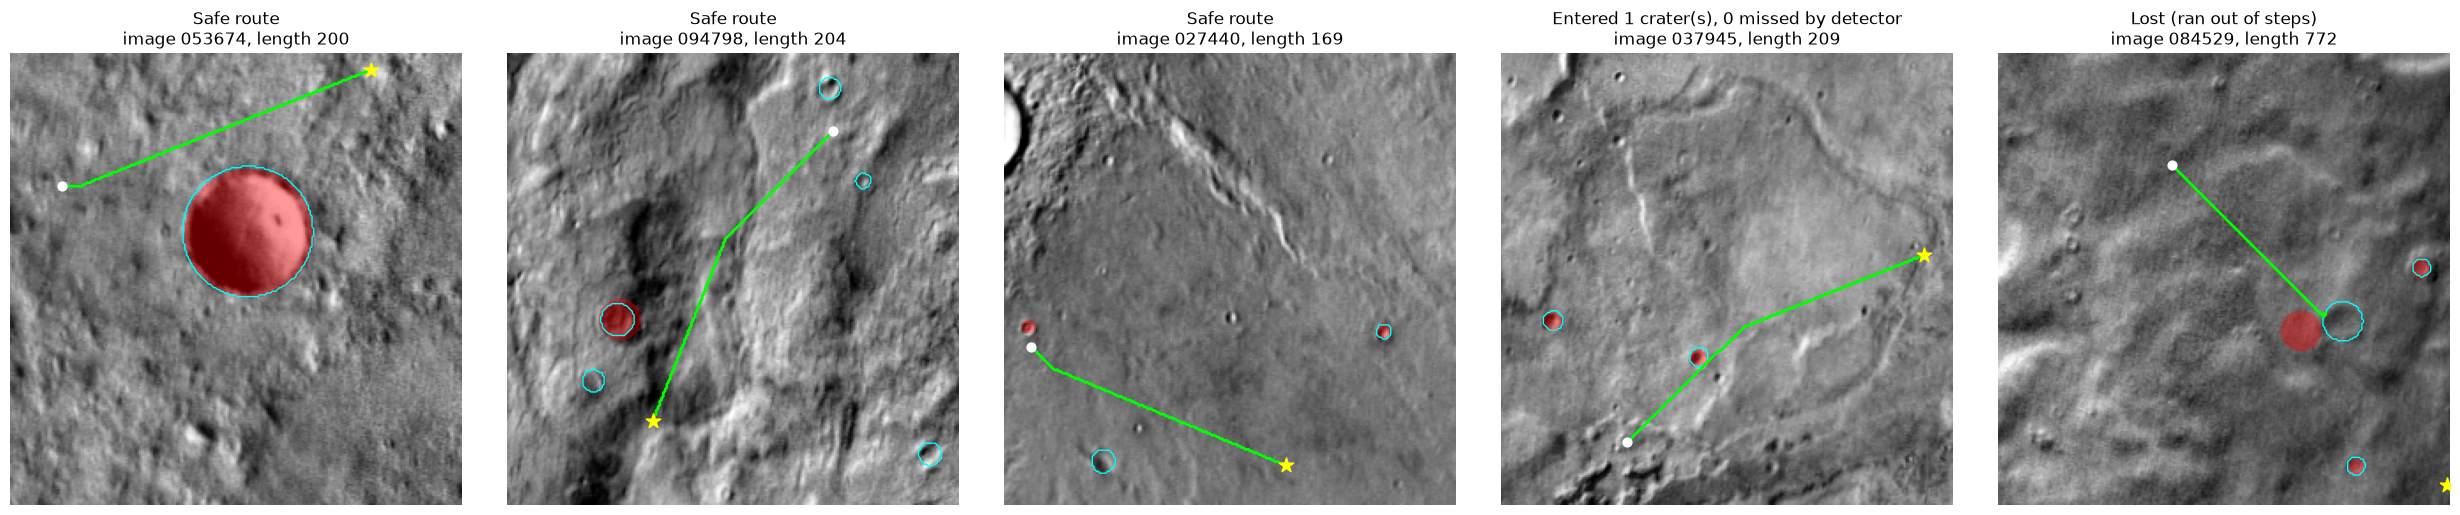

In [18]:
safe = [r for r in results if r["reached"] and r["entered"] == 0][:3]
own_mistake = [r for r in results if r["entered"] > r["entered_missed"]][:1]
lost = [r for r in results if not r["reached"]][:1]
chosen = safe + own_mistake + lost

fig, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 5))

for ax, r in zip(axes, chosen):
    image_id = r["image_id"]
    true_map, detected_map = get_maps(image_id)
    path, reached = drive(detected_map, tuple(r["start"]), tuple(r["goal"]))
    ys, xs = zip(*path)

    ax.imshow(Image.open(images_path / f"{image_id}.png"), cmap="gray")
    ax.imshow(np.ma.masked_where(true_map == 0, true_map), cmap="autumn", alpha=0.4)   # true craters
    ax.contour(detected_map, levels=[0.5], colors="cyan", linewidths=1)               # detected craters
    ax.plot(xs, ys, color="lime", linewidth=2)                                        # Rover 2's route
    ax.scatter(xs[0], ys[0], color="white", s=40, zorder=3)                           # start
    ax.scatter(r["goal"][1], r["goal"][0], color="yellow", marker="*", s=120, zorder=3)   # goal

    if not reached:
        title = "Lost (ran out of steps)"
    elif r["entered"] == 0:
        title = "Safe route"
    else:
        title = f"Entered {r['entered']} crater(s), {r['entered_missed']} missed by detector"
    ax.set_title(f"{title}\nimage {image_id}, length {r['length']:.0f}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "routes.png", dpi=150, bbox_inches="tight")
plt.show()

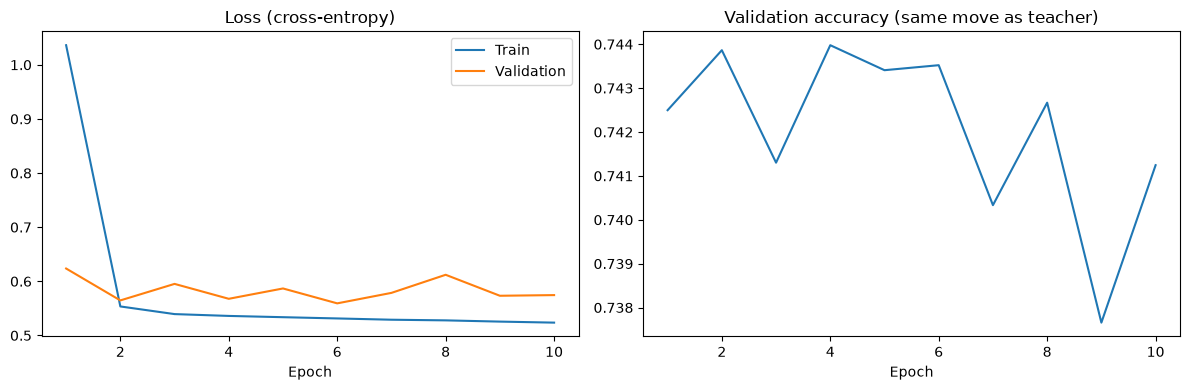

model: MLP 227 -> 128 (ReLU) -> 8, 30,216 parameters
input: 15x15 window of the Faster R-CNN detected map (cutoff 0.8, outside the image = crater) + 2-number direction to goal
labels: teacher moves from A* on the true crater map (behavior cloning, no DAgger)
training data: 87,721 train examples from 500 train routes, 17,561 val examples from 100 val routes
loss: CrossEntropyLoss | optimizer: Adam, lr=1e-3 | batch size: 256 | epochs: 10
best val accuracy: 0.7440
driving: reached = within 2 cells of goal; lost = more than 3x the straight-line distance in steps; off-map moves = stay
test: the same 1,000 test routes as Rover 1

Rover 1: {'reached goal': '99.9%', 'runs that entered a crater': '9.3%', 'craters entered': 99, '  missed by detector': 27, 'avg path length (reached runs)': '208.6'}
Rover 2: {'reached goal': '99.6%', 'runs that entered a crater': '12.5%', 'craters entered': 132, '  missed by detector': 32, 'avg path length (reached runs)': '206.5'}



In [19]:
# training curves
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_range, history["train_loss"], label="Train")
ax1.plot(epochs_range, history["val_loss"], label="Validation")
ax1.set_title("Loss (cross-entropy)")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(epochs_range, history["val_acc"])
ax2.set_title("Validation accuracy (same move as teacher)")
ax2.set_xlabel("Epoch")

plt.tight_layout()
plt.savefig(run_dir / "curves.png", dpi=150, bbox_inches="tight")
plt.show()

# notes
s1, s2 = summary(rover1_results), summary(results)
notes = f"""model: MLP 227 -> 128 (ReLU) -> 8, {sum(p.numel() for p in model.parameters()):,} parameters
input: 15x15 window of the Faster R-CNN detected map (cutoff 0.8, outside the image = crater) + 2-number direction to goal
labels: teacher moves from A* on the true crater map (behavior cloning, no DAgger)
training data: {len(Y_train):,} train examples from 500 train routes, {len(Y_val):,} val examples from 100 val routes
loss: CrossEntropyLoss | optimizer: Adam, lr=1e-3 | batch size: 256 | epochs: {epochs}
best val accuracy: {max(history["val_acc"]):.4f}
driving: reached = within 2 cells of goal; lost = more than 3x the straight-line distance in steps; off-map moves = stay
test: the same 1,000 test routes as Rover 1

Rover 1: {s1}
Rover 2: {s2}
"""
(run_dir / "notes.txt").write_text(notes)
print(notes)